# Exploratory Data Analysis for the Australian Weather Dataset
For this assignment, the exploratory data analysis is split from the rest of the tasks to make the code less connected. This is done after experience gained from the previous assignment that the EDA would be shuffled around the notebook depending on which other aspects of the task needed to be done in which order. This also makes it easier to work on the project in parallel and ensure that once the EDA is finished, it does not have to tested after every change in the main notebook. In summary, the EDA for the Australian Weather Dataset is decoupled from the main notebook to get the advantages of loosely coupled code.



In [2]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from markdown_it.rules_inline.backticks import regex
from pandas.core.interchange.dataframe_protocol import Column

plt.style.use('default')
import seaborn as sns
from sklearn.preprocessing import TargetEncoder, OrdinalEncoder

In [3]:
eda_dataset = pd.read_csv('Dataset/weatherAUS.csv')
pd.DataFrame(eda_dataset)
eda_dataset.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [4]:
eda_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null   float64


In [5]:
eda_dataset.isna().sum()

Date                 0
Location             0
MinTemp           1485
MaxTemp           1261
Rainfall          3261
Evaporation      62790
Sunshine         69835
WindGustDir      10326
WindGustSpeed    10263
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am      1767
WindSpeed3pm      3062
Humidity9am       2654
Humidity3pm       4507
Pressure9am      15065
Pressure3pm      15028
Cloud9am         55888
Cloud3pm         59358
Temp9am           1767
Temp3pm           3609
RainToday         3261
RainTomorrow      3267
dtype: int64

Rows with missing values in the target value are dropped since they offer no value to supervised learning methods.

In [6]:
eda_dataset = eda_dataset.dropna(subset=["RainTomorrow"])

eda_dataset.isna().sum()

Date                 0
Location             0
MinTemp            637
MaxTemp            322
Rainfall          1406
Evaporation      60843
Sunshine         67816
WindGustDir       9330
WindGustSpeed     9270
WindDir9am       10013
WindDir3pm        3778
WindSpeed9am      1348
WindSpeed3pm      2630
Humidity9am       1774
Humidity3pm       3610
Pressure9am      14014
Pressure3pm      13981
Cloud9am         53657
Cloud3pm         57094
Temp9am            904
Temp3pm           2726
RainToday         1406
RainTomorrow         0
dtype: int64

Making a numerical dataset and a categorical dataset to make analysis easier

## Temporary Encoding
For certain parts of the analysis, such as the correlation heatmap, it is necessary to use encoded data. There is therefore a temporary encoding of the categorical and time series values connected to the dataset. The values are encoded in such a way that all parts of features are carried forward in the dataset, and that the encoding makes sense for the feature domain. For example, ordinal encoder is not used on location, since there is no inherent order (other than perhaps coordinate location) to them. Another example is that it may be that the year is unnecessary as a feature since historically rain is hard to predict based on yearly intervals. But, it is still included since this is the analysis part.


In [7]:
# Create a new encoded version of the dataset which will be used for certain parts of the analysis.
encoded_eda_dataset = eda_dataset.copy()

In [8]:
encoded_eda_dataset['RainTomorrow'] = encoded_eda_dataset['RainTomorrow'].replace({'No':0, 'Yes':1}).astype(float)

Encoding of categorical data

In [9]:
# Target encoding of location
x = encoded_eda_dataset[['Location']]
y = encoded_eda_dataset['RainTomorrow']

encoder = TargetEncoder()
encoded_eda_dataset['Location'] = encoder.fit_transform(x,y)

Encoding of numerical data

In [10]:
# Binary Encoding of RainToday
encoded_eda_dataset['RainToday'] = encoded_eda_dataset['RainToday'].replace({'No': 0, 'Yes': 1}).astype(float)

### Cyclical encoding

This dataset includes multiple features which have cyclical properties. This means that the order of the data is important, but there is a wrap-around of the order at the start and finish. The date includes seasonality, with certain patterns reoccurring depending on which time of year it is. For example, in Australia, rain is more common in the summer. The wind direction is also cyclical, since the direction loops around for every full loop. Ordinal encoding would not retain the wrap-around property that cyclical features contain. Cyclical encoding is used for these features instead.

The relevant features with cyclic properties are as follows:
- WindGustDir
- WindDir9am
- WindDir3am
- date: day
- date: month

A general function for encoding with cyclic data is created which takes a Pandas series object and its corresponding period length. The function returns the same pandas series, encoded for the given period. This encoding includes both a cosine and sine wave fitted version of the Pandas series. Both are needed to keep track of the cycle, since multiple values share the same sine and cosine values in the same cycle. The function only works for numerical data.


In [11]:
# Function that takes a Pandas series and a corresponding period.
# Only pass numerical series.
# def cyclicEncoder(series, period):
#     # Filter for missing values. (Not needed for main notebook.)
#     # To prevent missing values from ruining the encoding, a check is made with the following requirement:
#     missing = series.isna()
#     # If values are missing, they are simply passed through.
#     sin = np.where(missing, np.nan, np.sin(2*np.pi*series/period))
#     cos = np.where(missing, np.nan, np.cos(2*np.pi*series/period))
#     return sin, cos

def cyclicEncoder(series, period):

    sin = np.sin(2*np.pi*series/period)
    cos = np.cos(2*np.pi*series/period)
    return sin, cos



There is a more thorough way of doing the cyclical encoding, using fourier transform principles to find different frequencies each feature encapsulate. However, due to time constraints and what has been covered in this course, using the more advanced method of encoding is considered out of scope for this assignment.

#### Data Preparation

In [12]:
# Ready date related data
# Convert to Pandas datetime format
encoded_eda_dataset["Date"] = pd.to_datetime(encoded_eda_dataset["Date"])
# Extract year, month and day based on year.
# Year is already "pre encoded" and can be left untouched.
encoded_eda_dataset["Year"] = encoded_eda_dataset["Date"].dt.year
encoded_eda_dataset["Month"] = encoded_eda_dataset["Date"].dt.month
encoded_eda_dataset["DayOfYear"] = encoded_eda_dataset["Date"].dt.day_of_year

# For analysis, there is a benefit of separating the Date feature as well.
# Therefore, it is done to the unencoded dataset as well.

eda_dataset["Date"] = pd.to_datetime(eda_dataset["Date"])
eda_dataset["Month"] = eda_dataset["Date"].dt.month
eda_dataset["DayOfYear"] = eda_dataset["Date"].dt.day_of_year


In [13]:
# Ready wind related data
# Find the unique entries in the wind columns
encoded_eda_dataset["WindGustDir"].unique()

<StringArray>
[  'W', 'WNW', 'WSW',  'NE', 'NNW',   'N', 'NNE',  'SW', 'ENE', 'SSE',   'S',
  'NW',  'SE', 'ESE',   nan,   'E', 'SSW']
Length: 17, dtype: str

For analytical purposes, the missing values are kept. The rest of the values are manually encoded using domain knowledge.

In [14]:
encoded_eda_dataset['WindGustDir'] = encoded_eda_dataset['WindGustDir'].replace({'N': 16,
                                                                                 'NNE': 1,
                                                                                 'NE': 2,
                                                                                 'ENE': 3,
                                                                                 'E': 4,
                                                                                 'ESE': 5,
                                                                                 'SE': 6,
                                                                                 'SSE': 7,
                                                                                 'S': 8,
                                                                                 'SSW': 9,
                                                                                 'SW': 10,
                                                                                 'WSW': 11,
                                                                                 'W': 12,
                                                                                 'WNW': 13,
                                                                                 'NW': 14,
                                                                                 'NNW': 15,
                                                                                 }).astype(float)
# Floats has to be used for the nan objects to be translated to floats as well.
# Otherwise, the array with nans will be of dtype object which will cause the sin and cos
# functions from numpy to fail.

encoded_eda_dataset['WindDir9am'] = encoded_eda_dataset['WindDir9am'].replace({'N': 0,
                                                                                 'NNE': 1,
                                                                                 'NE': 2,
                                                                                 'ENE': 3,
                                                                                 'E': 4,
                                                                                 'ESE': 5,
                                                                                 'SE': 6,
                                                                                 'SSE': 7,
                                                                                 'S': 8,
                                                                                 'SSW': 9,
                                                                                 'SW': 10,
                                                                                 'WSW': 11,
                                                                                 'W': 12,
                                                                                 'WNW': 13,
                                                                                 'NW': 14,
                                                                                 'NNW': 15,
                                                                                 }).astype(float)

encoded_eda_dataset['WindDir3pm'] = encoded_eda_dataset['WindDir3pm'].replace({'N': 0,
                                                                                 'NNE': 1,
                                                                                 'NE': 2,
                                                                                 'ENE': 3,
                                                                                 'E': 4,
                                                                                 'ESE': 5,
                                                                                 'SE': 6,
                                                                                 'SSE': 7,
                                                                                 'S': 8,
                                                                                 'SSW': 9,
                                                                                 'SW': 10,
                                                                                 'WSW': 11,
                                                                                 'W': 12,
                                                                                 'WNW': 13,
                                                                                 'NW': 14,
                                                                                 'NNW': 15,
                                                                                 }).astype(float)
# Check for array datatype and encoded values.
encoded_eda_dataset['WindGustDir'].unique()

array([12., 13., 11.,  2., 15., 16.,  1., 10.,  3.,  7.,  8., 14.,  6.,
        5., nan,  4.,  9.])

#### Use the Cyclic Encoding Function

In [15]:
# For future use
# encoded_eda_dataset["Month_Sin"],encoded_eda_dataset["Month_Cos"]  = cyclicEncoder(encoded_eda_dataset["Month"], MONTH_PERIOD)
# encoded_eda_dataset["Day_Sin"],encoded_eda_dataset["Day_Cos"]  = cyclicEncoder(encoded_eda_dataset["DayOfYear"], encoded_eda_dataset['Days_in_year'])
# encoded_eda_dataset["WindGustDir_Sin"],encoded_eda_dataset["WindGustDir_Cos"]  = cyclicEncoder(encoded_eda_dataset["WindGustDir"], WIND_DIR)
# encoded_eda_dataset["WindDir9am_Sin"],encoded_eda_dataset["WindDir9am_Cos"]  = cyclicEncoder(encoded_eda_dataset["WindDir9am"], WIND_DIR)
# encoded_eda_dataset["WindDir3pm_Sin"],encoded_eda_dataset["WindDir3pm_Cos"]  = cyclicEncoder(encoded_eda_dataset["WindDir3pm"], WIND_DIR)

In [16]:
# Period lengths:
# The period lengths are derived from the amount of months per year,
# and the granularity of wind directions chosen by the data scientists who produced the dataset.
MONTH_PERIOD = 12
WIND_DIR = 16
# The day is more complicated since it varies based on the year.
# A new temporary pandas series is created, and the amount of days a year has is placed inside the series for each day.
year = encoded_eda_dataset['Year']
isLeapYear = ((year % 4 == 0) & (year % 100 != 0)) | (year % 400 == 0)
encoded_eda_dataset['DaysInYear'] = np.select([isLeapYear], [366], default=365)


encoded_eda_dataset["Month_Sin"],encoded_eda_dataset["Month_Cos"]  = cyclicEncoder(encoded_eda_dataset["Month"], MONTH_PERIOD)
encoded_eda_dataset["Day_Sin"],encoded_eda_dataset["Day_Cos"]  = cyclicEncoder(encoded_eda_dataset["DayOfYear"], encoded_eda_dataset['DaysInYear'])
encoded_eda_dataset["WindGustDir_Sin"],encoded_eda_dataset["WindGustDir_Cos"]  = cyclicEncoder(encoded_eda_dataset["WindGustDir"], WIND_DIR)
encoded_eda_dataset["WindDir9am_Sin"],encoded_eda_dataset["WindDir9am_Cos"]  = cyclicEncoder(encoded_eda_dataset["WindDir9am"], WIND_DIR)
encoded_eda_dataset["WindDir3pm_Sin"],encoded_eda_dataset["WindDir3pm_Cos"]  = cyclicEncoder(encoded_eda_dataset["WindDir3pm"], WIND_DIR)

# Remove redundant columns
encoded_eda_dataset.drop(["Date", "DaysInYear", "Month", "DayOfYear", "WindGustDir", "WindDir9am", "WindDir3pm"], axis=1, inplace=True)

In [17]:
encoded_eda_dataset["Month_Sin"].unique()
# encoded_eda_dataset["Month_Cos"].unique()
# encoded_eda_dataset["WindGustDir_Sin"].unique()

array([-2.44929360e-16,  5.00000000e-01,  8.66025404e-01,  1.00000000e+00,
        8.66025404e-01,  1.22464680e-16, -5.00000000e-01, -8.66025404e-01,
       -1.00000000e+00, -8.66025404e-01, -5.00000000e-01])

### Check encoding

In [18]:
encoded_eda_dataset.head()

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,...,Month_Sin,Month_Cos,Day_Sin,Day_Cos,WindGustDir_Sin,WindGustDir_Cos,WindDir9am_Sin,WindDir9am_Cos,WindDir3pm_Sin,WindDir3pm_Cos
0,0.204953,13.4,22.9,0.6,NaN,NaN,44.0,20.0,24.0,71.0,...,-2.449294e-16,1.0,-0.492548,0.870285,-1.000000,-1.836970e-16,-1.000000,-1.836970e-16,-0.923880,3.826834e-01
1,0.203588,7.4,25.1,0.0,NaN,NaN,44.0,4.0,22.0,44.0,...,-2.449294e-16,1.0,-0.477536,0.878612,-0.923880,3.826834e-01,-0.382683,9.238795e-01,-0.923880,-3.826834e-01
2,0.206716,12.9,25.7,0.0,NaN,NaN,46.0,19.0,26.0,38.0,...,-2.449294e-16,1.0,-0.462383,0.886680,-0.923880,-3.826834e-01,-1.000000,-1.836970e-16,-0.923880,-3.826834e-01
3,0.206716,9.2,28.0,0.0,NaN,NaN,24.0,11.0,9.0,45.0,...,-2.449294e-16,1.0,-0.447094,0.894487,0.707107,7.071068e-01,0.707107,-7.071068e-01,1.000000,6.123234e-17
4,0.204953,17.5,32.3,1.0,NaN,NaN,41.0,7.0,20.0,82.0,...,-2.449294e-16,1.0,-0.431673,0.902030,-1.000000,-1.836970e-16,0.923880,3.826834e-01,-0.707107,7.071068e-01


## Data Analysis

### Univariate Analysis

In [19]:
# See how many different locations are used.
eda_dataset["Location"].nunique()

49

In [20]:
# Check if every location has the same amount of observations
eda_dataset.value_counts("Location")

Location
Canberra            3418
Sydney              3337
Perth               3193
Darwin              3192
Hobart              3188
Brisbane            3161
Adelaide            3090
Bendigo             3034
Townsville          3033
AliceSprings        3031
MountGambier        3030
Ballarat            3028
Launceston          3028
Albany              3016
Albury              3011
MelbourneAirport    3009
PerthAirport        3009
Mildura             3007
SydneyAirport       3005
Nuriootpa           3002
Sale                3000
Watsonia            2999
Tuggeranong         2998
Portland            2996
Woomera             2990
Cobar               2988
Cairns              2988
Wollongong          2983
GoldCoast           2980
WaggaWagga          2976
NorfolkIsland       2964
Penrith             2964
Newcastle           2955
SalmonGums          2955
CoffsHarbour        2953
Witchcliffe         2952
Richmond            2951
Dartmoor            2943
NorahHead           2929
BadgerysCreek   

As can be seen from the result, the gap between the location with the most and fourth least entries is small, but not negligible. The gap is 3436 - 3001 = 435, which is an increase of about $\frac{435}{3001}$ $\cdot$ 100% $\approx$ 14.5% of the smallest value. This means that the model will be slightly more skewed towards the patterns seen in Canberra and Sydney, compared to the rest of the locations, with three exceptions. The last three locations only have 1578 observations. This is about half of the other 46 locations. These three location will therefore have less of an impact in the model training. It is easier for their patterns to be overshadowed by the other locations which have more instances.


### Multivariate Analysis

<Axes: >

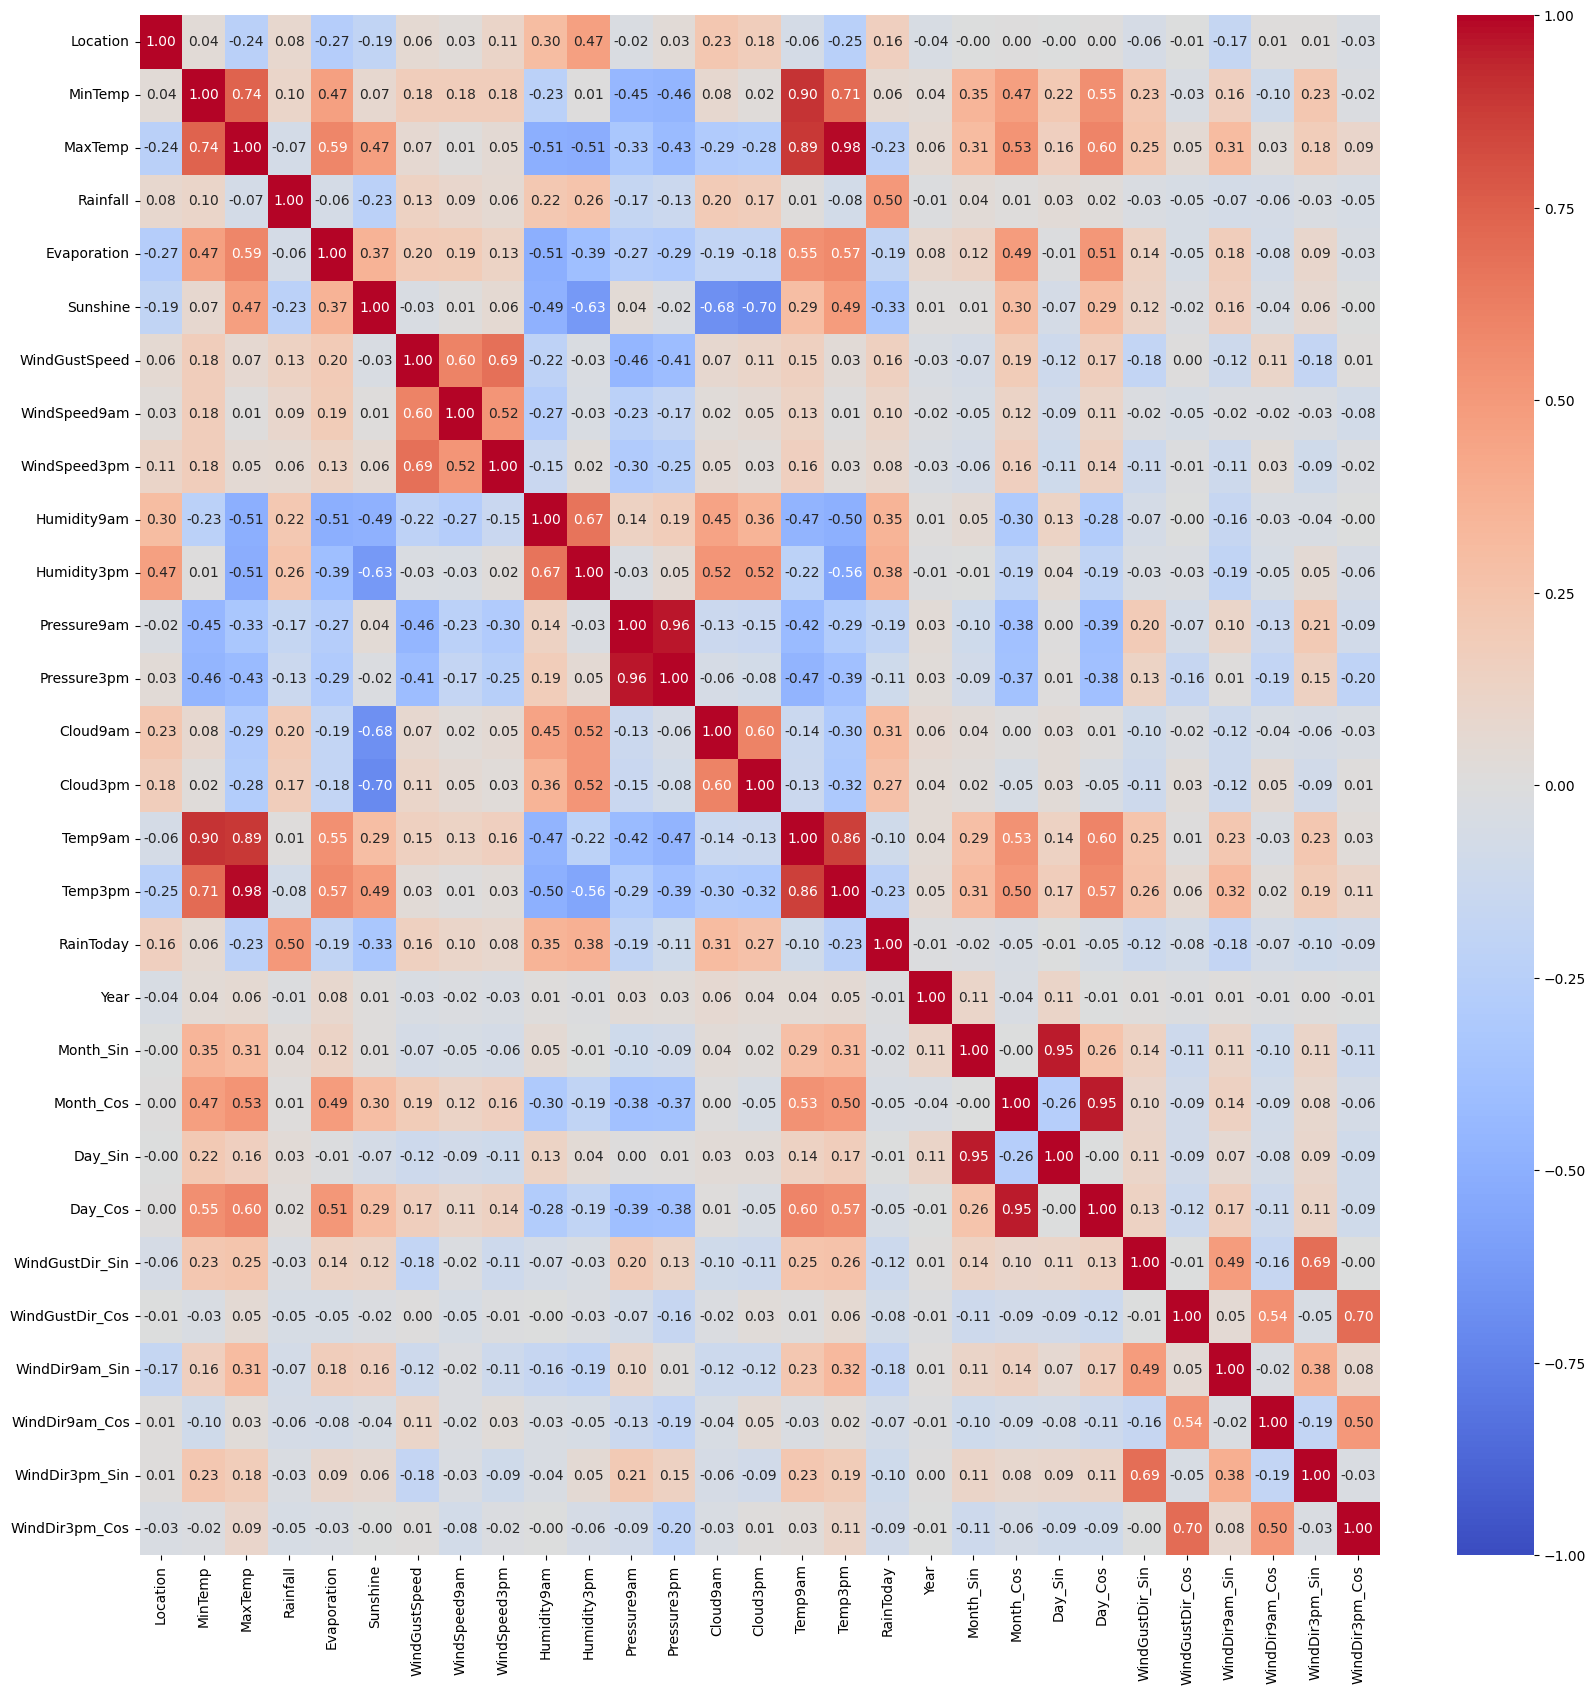

In [21]:
# Correlation heatmap.

# Computes the pairwise correlation between each feature.
correlation = encoded_eda_dataset.drop("RainTomorrow", axis=1).corr()

# Shows the correlation between the features in a heatmap.
plt.figure(figsize=(20, 20))
sns.heatmap(correlation, cmap='coolwarm', annot=True, fmt='.2f', vmin=-1, vmax=1)


#### Results

Points to mention:
- Obvious correlations
- It's good that year isn't correlated to any specific features.
- We can accept the correlations
- Cos and Sin are correlated by design


<Axes: >

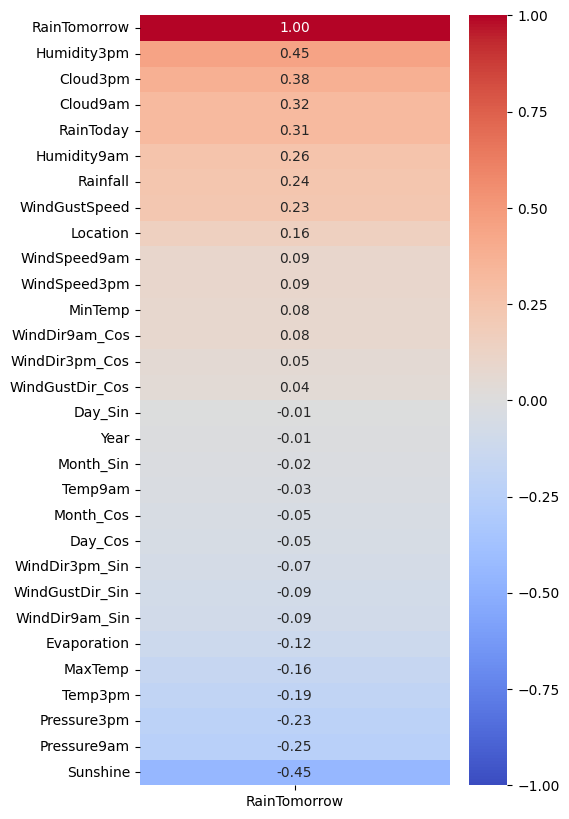

In [22]:
# Correlation heatmap part 2.

# Computes the pairwise correlation between each feature and the target value.
correlation = encoded_eda_dataset.corr()

# Shows the correlation between the target value and features ordered from the most positive correlation to the most negative correlation.
plt.figure(figsize=(5, 10))
sns.heatmap(correlation[['RainTomorrow']].sort_values(by=['RainTomorrow'],ascending=False), cmap='coolwarm', annot=True, fmt='.2f', vmin=-1, vmax=1)

#### Scatterplot
Some of the most correlated features are investigated further. Additionally, two sets of uncorrelated features are looked at. These scatterplots show correlation if the datapoints follow a straight line with a rate of increase different from zero.

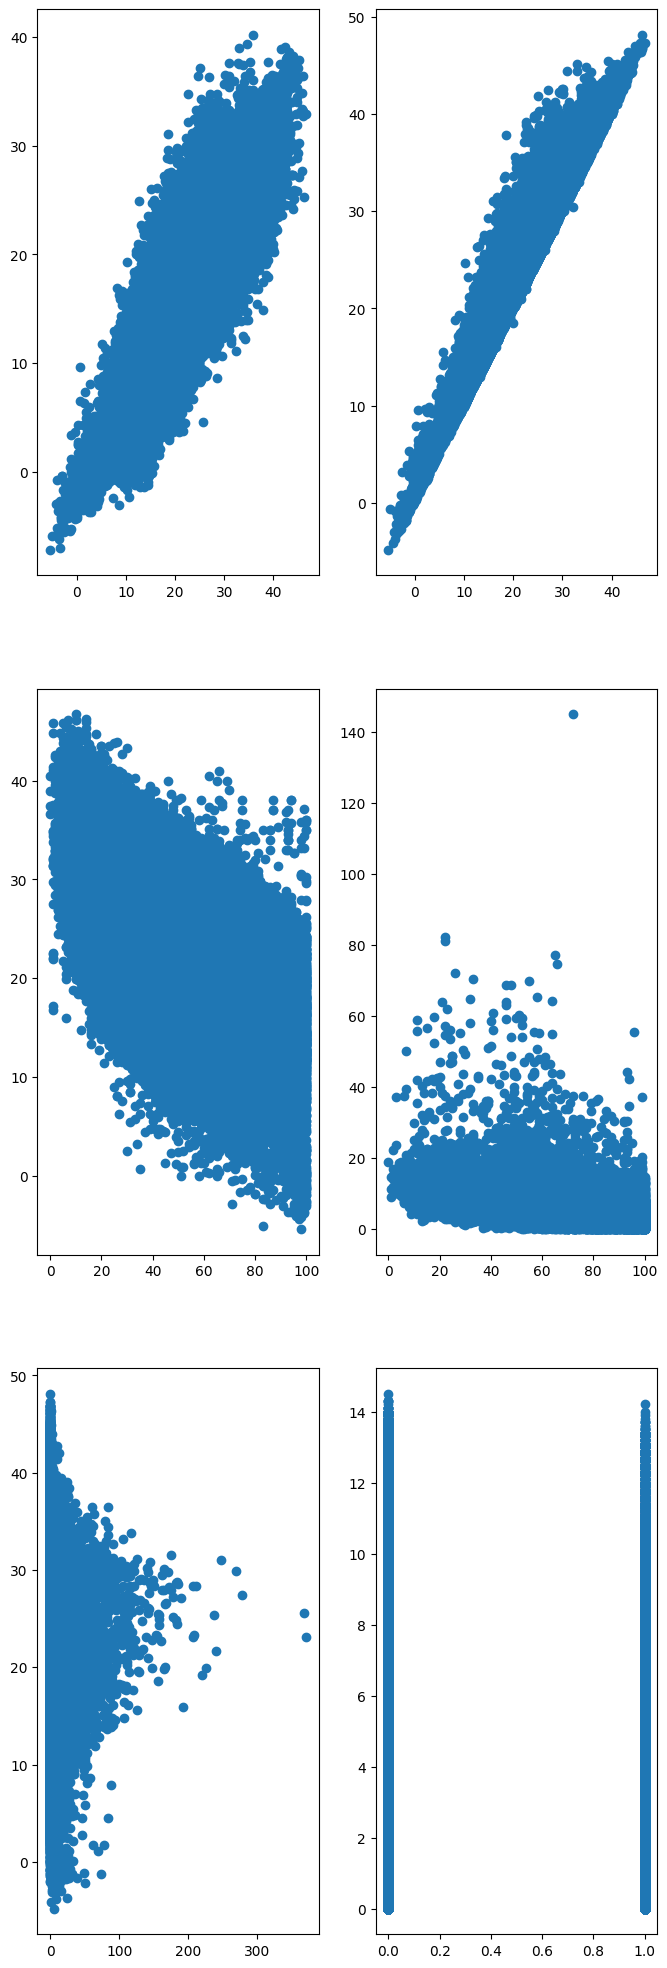

In [23]:
# Scatterplot.
fig, ax = plt.subplots(3, 2, figsize=(8,25))

ax[0, 0].scatter(encoded_eda_dataset['Temp3pm'], encoded_eda_dataset['Temp9am'])
ax[0, 1].scatter(encoded_eda_dataset['Temp3pm'], encoded_eda_dataset['MaxTemp'])
ax[1, 0].scatter(encoded_eda_dataset['Humidity3pm'], encoded_eda_dataset['Temp3pm'])
ax[1, 1].scatter(encoded_eda_dataset['Humidity9am'], encoded_eda_dataset['Evaporation'])
ax[2, 0].scatter(encoded_eda_dataset['Rainfall'], encoded_eda_dataset['MaxTemp'])
ax[2, 1].scatter(encoded_eda_dataset['RainToday'], encoded_eda_dataset['Sunshine'])

#### Results

#### Pairplot
For a larger overview of the correlation between features, a pairplot is provided to see most features' correlation. To keep the figure readable, both in terms of size of the overall pair plot and the readability of the individual graphs, the most discrete columns are excluded. This includes the target value. Additionally, where there is a value for the morning and afternoon, only the afternoon value is represented in the plot.

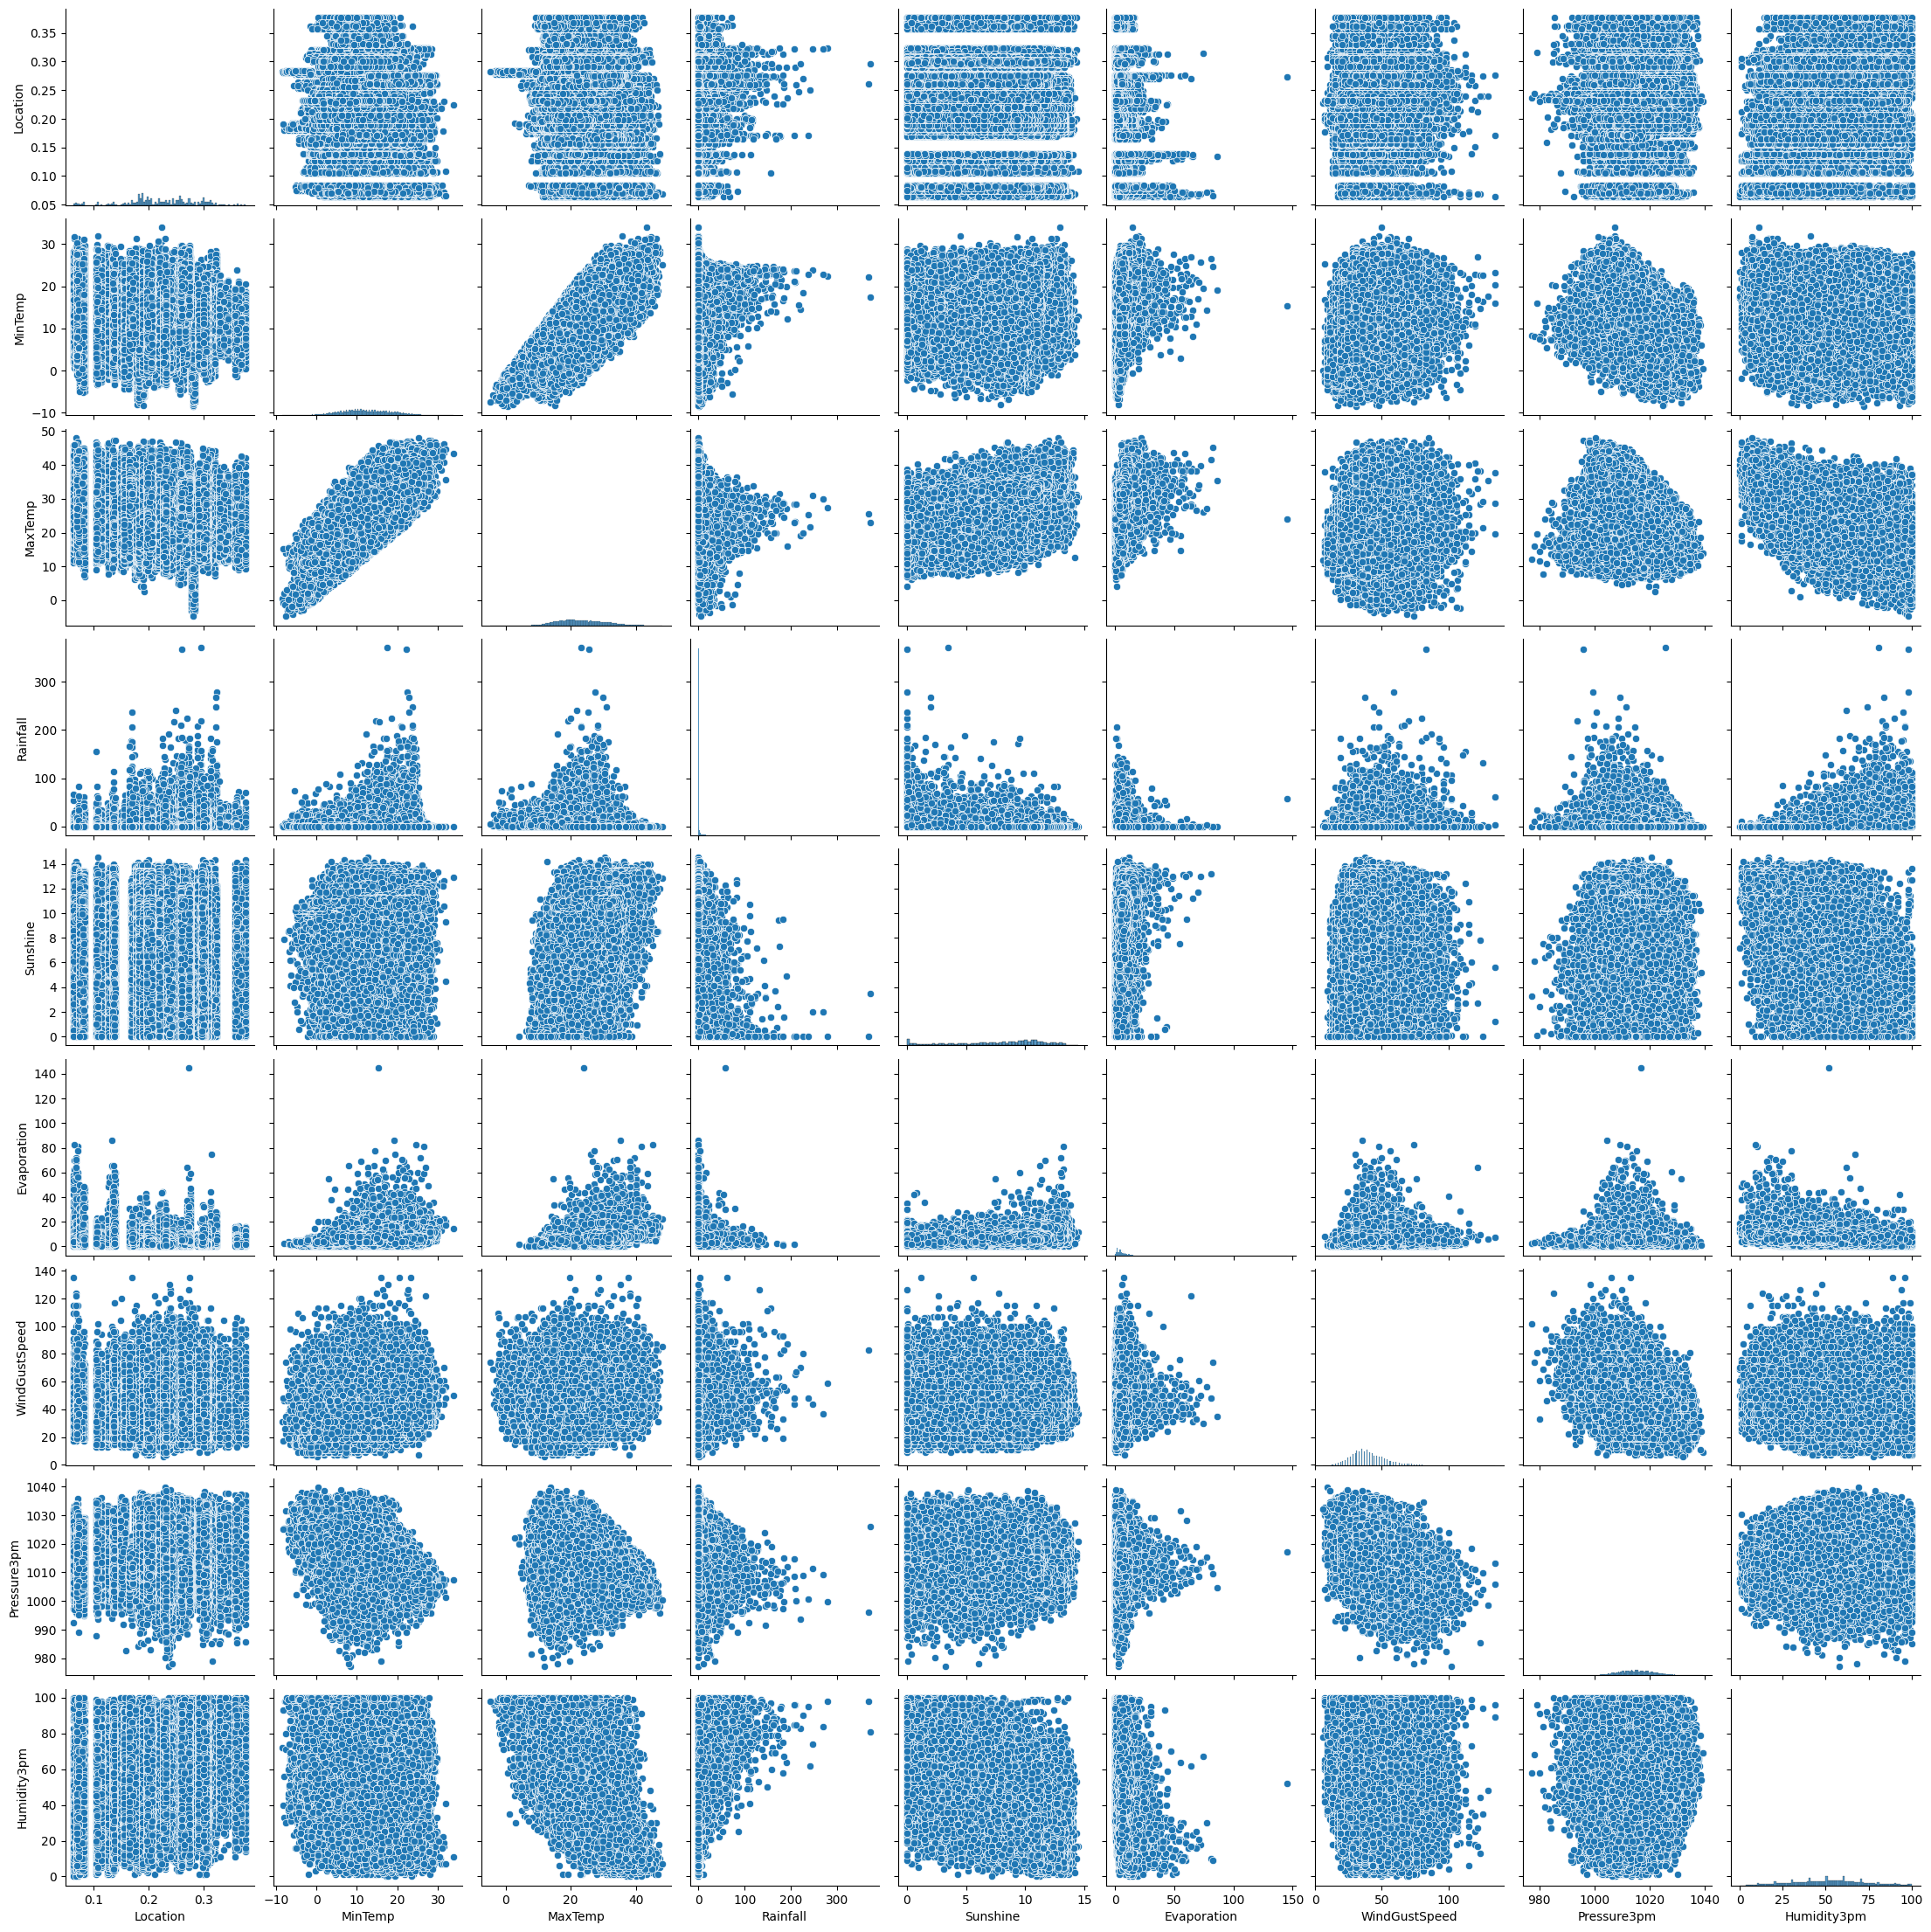

In [24]:
sns.pairplot(encoded_eda_dataset, vars=["Location", "MinTemp", "MaxTemp", "Rainfall", "Sunshine", "Evaporation", "WindGustSpeed", "Pressure3pm", "Humidity3pm"])

#### Results

#### Crosstables
Six crosstables are provided as an alternative to scatterplots for discrete data with few possible values.
Four of them, marked with green mapping, is between features. The other two are between a feature and the target value.

The first crosstable provided was the one which needed the most "tuning", or work, to get presentable. As such, four examples of the crosstable is provided, each subsequently improving on the last one.

In [25]:
# To optimize wind directions in the crosstables, making them more readable,
# temporary columns for wind directions are provided.

# This is done by replacing the new columns using simple regular expressions.
eda_dataset["Compact_WindGustDir"] = eda_dataset["WindGustDir"].replace(["N.*","E.*", "S.*", "W.*" ], ["North", "East", "South", "West"], regex=True)
eda_dataset["Compact_WindDir3pm"] = eda_dataset["WindDir3pm"].replace(["N.*","E.*", "S.*", "W.*" ], ["North", "East", "South", "West"], regex=True)
eda_dataset["Compact_WindDir9am"] = eda_dataset["WindDir9am"].replace(["N.*","E.*", "S.*", "W.*" ], ["North", "East", "South", "West"], regex=True)

<Axes: xlabel='RainTomorrow', ylabel='Sunshine'>

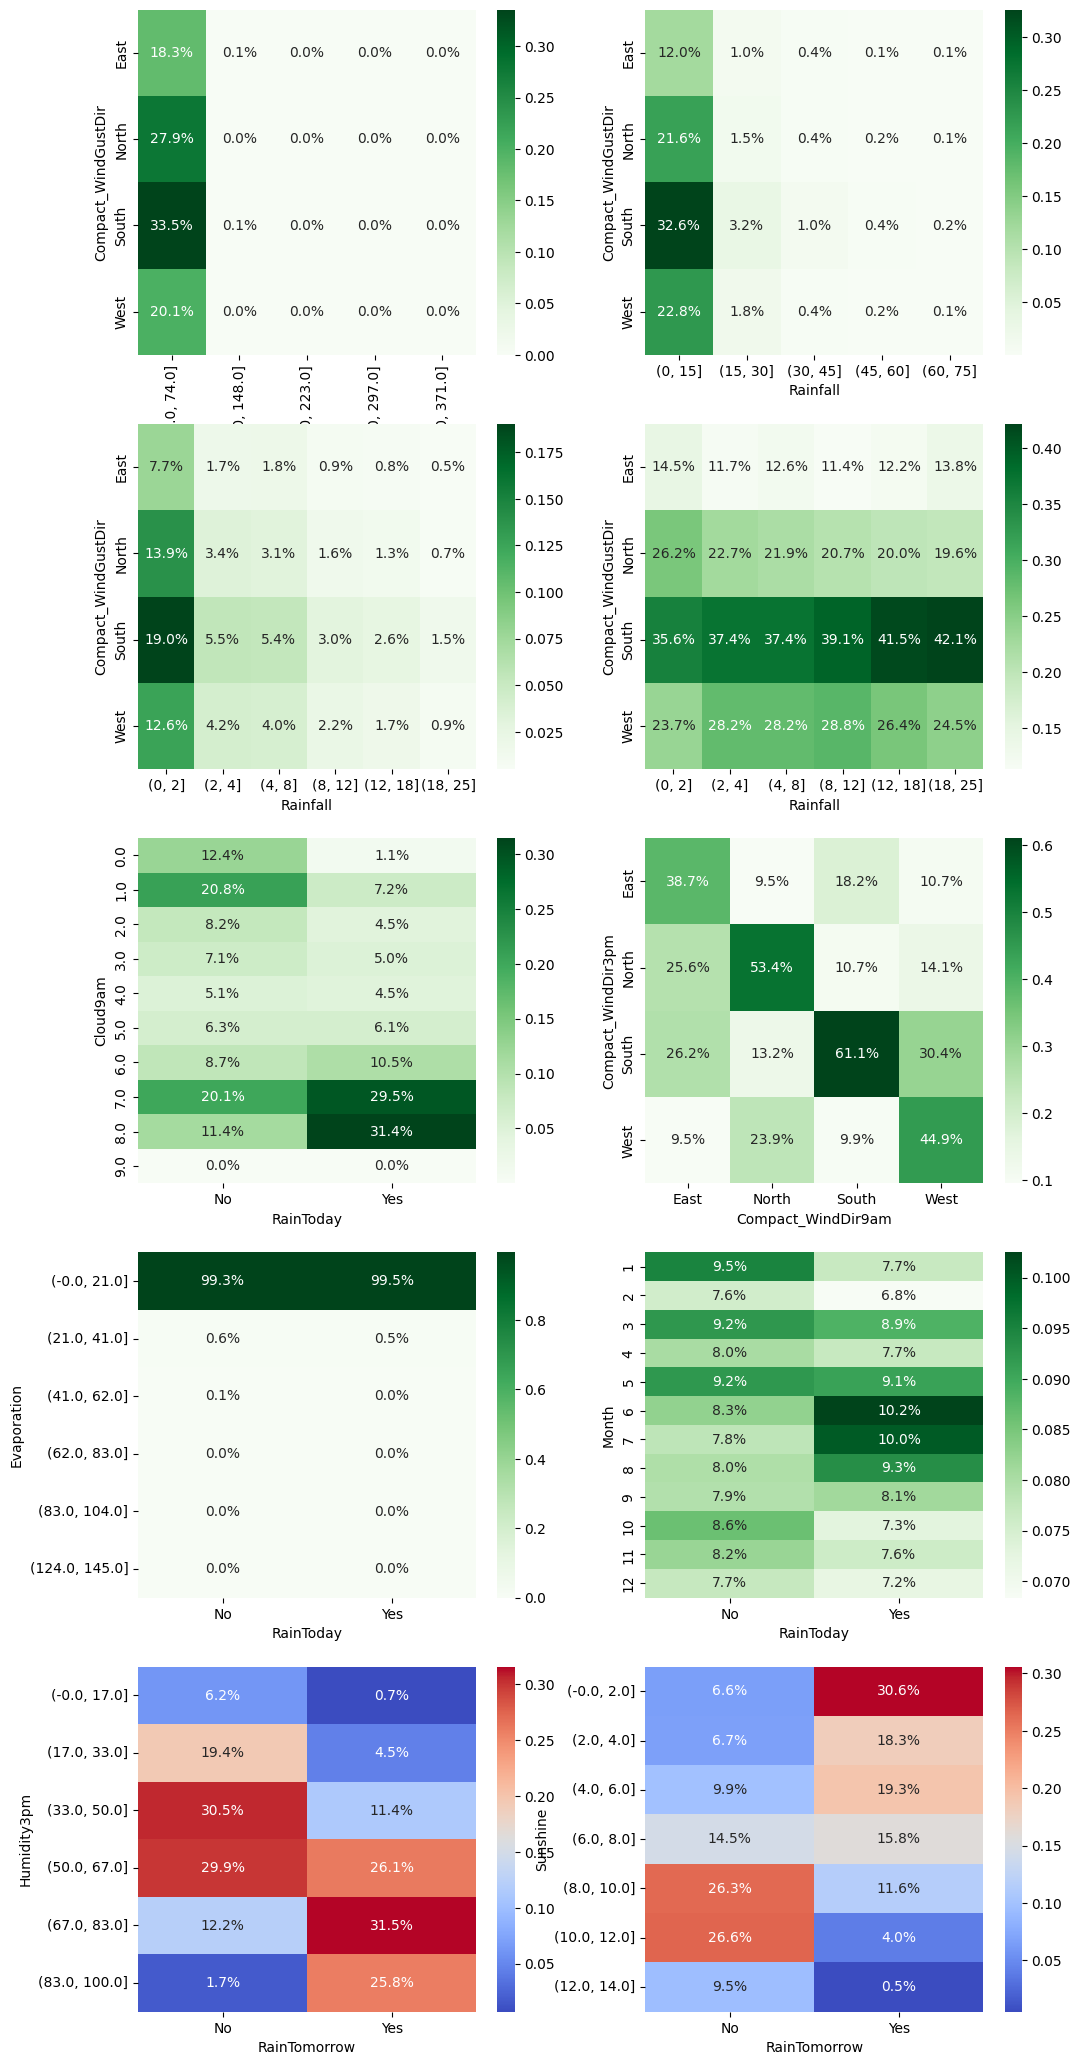

In [36]:
# Crosstables.
fig, ax = plt.subplots(5, 2, figsize=(12,26))


# Crosstables in between two features.
# Grouping/binning is used to make continuous features, or discrete features with many possible
# values more readable.
rainfall_grouped = pd.cut(eda_dataset["Rainfall"], 5, precision=0)
xtable1 = pd.crosstab(eda_dataset['Compact_WindGustDir'],
                      rainfall_grouped, normalize=True)
# If one looks at the first crosstable, it is clear rainfall higher than 74% are outliers.
# To get a better picture of the actual
bins = [0, 15, 30, 45, 60, 75]
rainfall_grouped = pd.cut(eda_dataset["Rainfall"], bins, precision=0)
xtable2 = pd.crosstab(eda_dataset['Compact_WindGustDir'],
                      rainfall_grouped, normalize=True)
# Further investigation reveals that it can be narrowed down even further.
# The bins are also unevenly distributed to get a better distribution of the percentages.
bins = [0, 2, 4, 8, 12, 18, 25]
rainfall_grouped = pd.cut(eda_dataset["Rainfall"], bins, precision=0)
xtable3 = pd.crosstab(eda_dataset['Compact_WindGustDir'],
                      rainfall_grouped, normalize=True)
# Lastly, the cells are normalized based on the column to better see the correlation
# between the features.
xtable4 = pd.crosstab(eda_dataset['Compact_WindGustDir'],
                      rainfall_grouped, normalize="columns")


xtable5 = pd.crosstab(eda_dataset['Cloud9am'],
                      eda_dataset['RainToday'], normalize="columns")

xtable6 = pd.crosstab(eda_dataset['Compact_WindDir3pm'],
                      eda_dataset['Compact_WindDir9am'], normalize="columns")

evaporationGrouped = pd.cut(eda_dataset["Evaporation"], 7, precision=0)
xtable7 = pd.crosstab(evaporationGrouped,
                      eda_dataset['RainToday'], normalize="columns")

xtable8 = pd.crosstab(eda_dataset['Month'],
                      eda_dataset['RainToday'], normalize="columns")

# Crosstables between features and target value.
# More binning of continuous features:
humidityGrouped = pd.cut(eda_dataset["Humidity3pm"], 6, precision=0)
xtable9 = pd.crosstab(humidityGrouped,
                      eda_dataset['RainTomorrow'], normalize="columns")

sunshineGrouped = pd.cut(eda_dataset["Sunshine"], 7, precision=0)
xtable10 = pd.crosstab(sunshineGrouped,
                      eda_dataset['RainTomorrow'], normalize="columns")


# Show the crosstables as heatmaps.
# Tables between features.
sns.heatmap(xtable1, cmap='Greens', annot=True, fmt='.1%', ax=ax[0, 0])
sns.heatmap(xtable2, cmap='Greens', annot=True, fmt='.1%', ax=ax[0, 1])
sns.heatmap(xtable3, cmap='Greens', annot=True, fmt='.1%', ax=ax[1, 0])
sns.heatmap(xtable4, cmap='Greens', annot=True, fmt='.1%', ax=ax[1, 1])
sns.heatmap(xtable5, cmap='Greens', annot=True, fmt='.1%', ax=ax[2, 0])
sns.heatmap(xtable6, cmap='Greens', annot=True, fmt='.1%', ax=ax[2, 1])
sns.heatmap(xtable7, cmap='Greens', annot=True, fmt='.1%', ax=ax[3, 0])
sns.heatmap(xtable8, cmap='Greens', annot=True, fmt='.1%', ax=ax[3, 1])

# Tables between a feature and the target.
sns.heatmap(xtable9, cmap='coolwarm', annot=True, fmt='.1%', ax=ax[4, 0])
sns.heatmap(xtable10, cmap='coolwarm', annot=True, fmt='.1%', ax=ax[4, 1])

<Axes: xlabel='Month', ylabel='DayOfYear'>

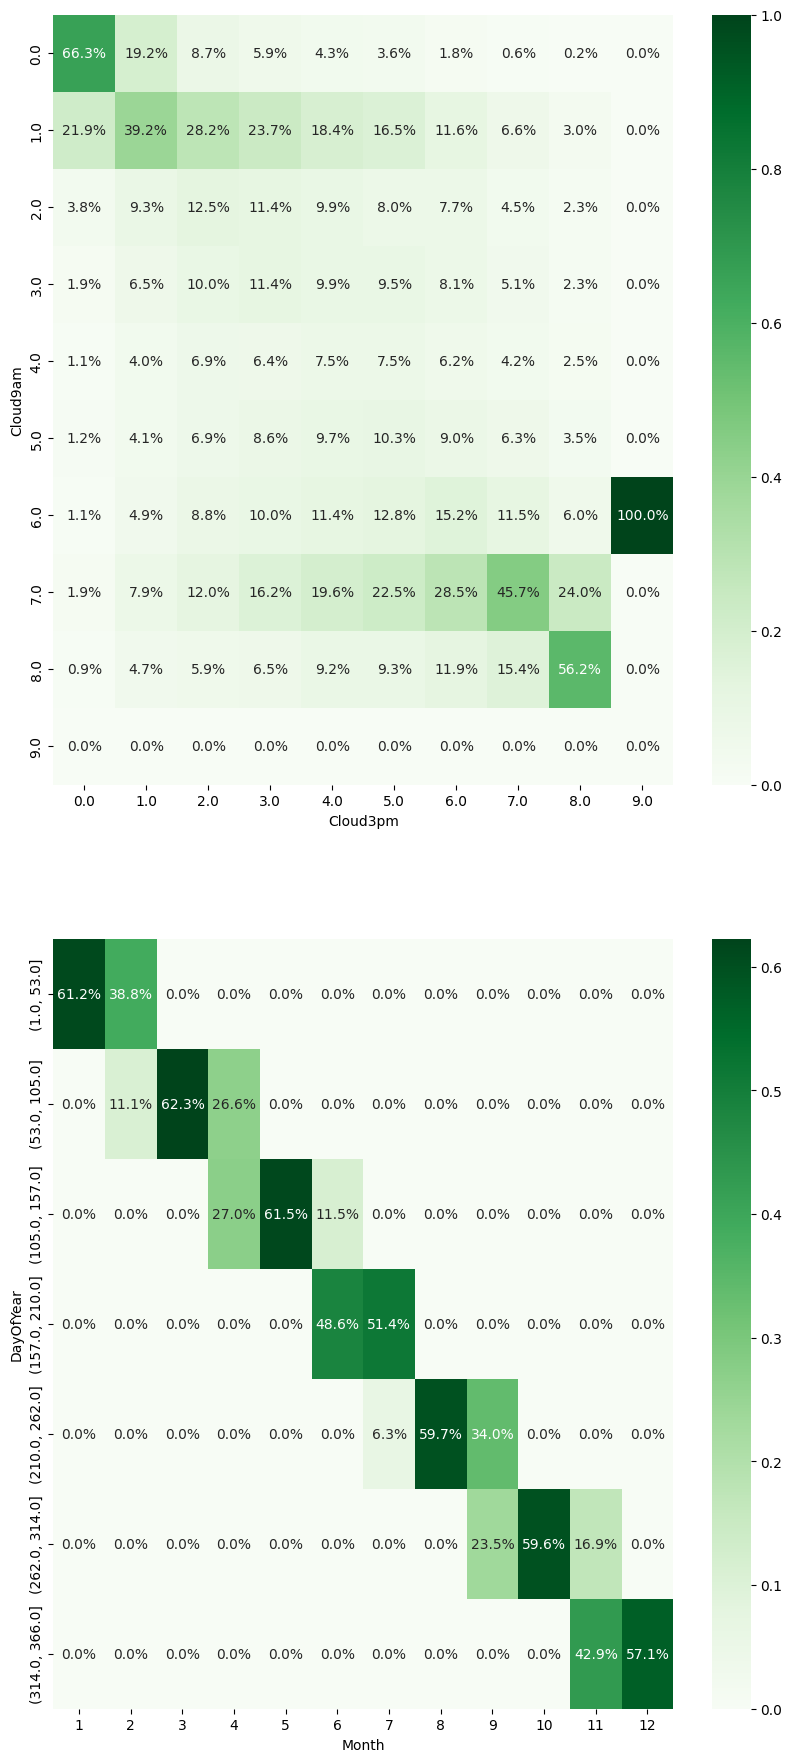

In [27]:
# Larger crosstables
# Both are between two features.

fig, ax = plt.subplots(2, 1, figsize=(10,22))

xtable1 = pd.crosstab(eda_dataset['Cloud9am'],
                      eda_dataset['Cloud3pm'], normalize="columns")
# There are a lot of days in a year, so they need to be grouped into smaller bins for
# the table to be readable.

days_grouped = pd.cut(eda_dataset["DayOfYear"], 7, precision=0)

xtable2 = pd.crosstab(days_grouped,
                      eda_dataset["Month"], normalize="index")


sns.heatmap(xtable1, cmap='Greens', annot=True, fmt='.1%', ax=ax[0])
sns.heatmap(xtable2, cmap='Greens', annot=True, fmt='.1%', ax=ax[1])

### Time Series Analysis